In [ ]:
from datetime import datetime                 # timestamp for the run log
from pathlib import Path                      # object-oriented file paths (works on Windows and Linux)

import numpy as np                            # numerical arrays and maths
import pandas as pd                           # tables (DataFrames)
import matplotlib.pyplot as plt               # charts
import statsmodels.api as sm                  # logistic regression with full statistical output
from scipy.stats import chi2_contingency, ks_2samp   # chi-square test and Kolmogorov-Smirnov
from sklearn.metrics import roc_auc_score, brier_score_loss   # AUC and Brier score
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF
from statsmodels.stats.proportion import proportion_confint  # Wilson confidence intervals

pd.set_option("display.max_columns", 200)     # print all columns instead of "..."
pd.set_option("display.max_rows", 400)        # print up to 400 rows
pd.set_option("display.width", 200)           # wider console output

# ---- Paths -------------------------------------------------------------------
PATH = Path(r"C:/Users/Ricardo/Downloads/risk_analyst_project/accepted_2007_to_2018q4.csv")

# ---- Population and time window ---------------------------------------------
TARGET_TERM = "36 months"     # keep 36-month loans: all of them have reached a final outcome
DEV_YEARS = (2012, 2014)      # development vintages (inclusive)
TEST_YEAR = 2015              # out-of-time test vintage
BAD_STATUS = ["Charged Off", "Default"]   # statuses coded as bad = 1
GOOD_STATUS = ["Fully Paid"]              # statuses coded as bad = 0

# ---- Selection and preprocessing thresholds ----------------------------------
MISSING_MAX = 0.05    # a variable is eligible only if <= 5% missing in EVERY vintage 2012-2015
IV_MIN = 0.02         # below this a variable has no predictive power
IV_MAX = 0.50         # above this a variable is suspicious (possible leakage)
CORR_MAX = 0.70       # |Spearman| at or above this means two variables are redundant
VIF_MAX = 5.0         # variables above this VIF are removed one at a time
WINSOR = (0.01, 0.99) # percentiles used to cap outliers
SKEW_MAX = 1.0        # skewness above this triggers a log1p transform
RARE_LEVEL = 0.01     # categories below 1% of the training data are pooled into one "RARE" group
                      # (named RARE, not OTHER, because OTHER/other are real Lending Club categories)
IV_BINS = 10          # number of quantile bins for IV (and for decile tables)

# ---- Economic assumptions (Q2) -----------------------------------------------
LGD_BASE = 0.65            # conservative LGD for unsecured consumer credit (range 60-70%)
FUNDING_BASE = 0.05        # annual funding cost of the lender (assumption)
AVG_LIFE_YEARS = 1.5       # average outstanding life of an amortising 3-year loan (about half of 3 years)
RISK_APPETITE = 0.10       # maximum acceptable bad rate of the approved portfolio (management assumption)
PD_STRESS = 1.20           # stress scenario: PDs 20% higher than estimated

# ---- Reproducibility ---------------------------------------------------------
RANDOM_STATE = 42     # fixed seed so bootstrap and samples give the same results every run
N_BOOT = 200          # bootstrap resamples for the AUC confidence interval

In [ ]:
from datetime import datetime                 # timestamp for the run log
from pathlib import Path                      # object-oriented file paths (works on Windows and Linux)

import numpy as np                            # numerical arrays and maths
import pandas as pd                           # tables (DataFrames)
import matplotlib.pyplot as plt               # charts
import statsmodels.api as sm                  # logistic regression with full statistical output
from scipy.stats import chi2_contingency, ks_2samp   # chi-square test and Kolmogorov-Smirnov
from sklearn.metrics import roc_auc_score, brier_score_loss   # AUC and Brier score
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF
from statsmodels.stats.proportion import proportion_confint  # Wilson confidence intervals

pd.set_option("display.max_columns", 200)     # print all columns instead of "..."
pd.set_option("display.max_rows", 400)        # print up to 400 rows
pd.set_option("display.width", 200)           # wider console output

# ---- Paths -------------------------------------------------------------------
PATH = Path(r"C:/Users/Ricardo/Downloads/risk_analyst_project/accepted_2007_to_2018q4.csv")

# ---- Population and time window ---------------------------------------------
TARGET_TERM = "36 months"     # keep 36-month loans: all of them have reached a final outcome
DEV_YEARS = (2012, 2014)      # development vintages (inclusive)
TEST_YEAR = 2015              # out-of-time test vintage
BAD_STATUS = ["Charged Off", "Default"]   # statuses coded as bad = 1
GOOD_STATUS = ["Fully Paid"]              # statuses coded as bad = 0

# ---- Selection and preprocessing thresholds ----------------------------------
MISSING_MAX = 0.05    # a variable is eligible only if <= 5% missing in EVERY vintage 2012-2015
IV_MIN = 0.02         # below this a variable has no predictive power
IV_MAX = 0.50         # above this a variable is suspicious (possible leakage)
CORR_MAX = 0.70       # |Spearman| at or above this means two variables are redundant
VIF_MAX = 5.0         # variables above this VIF are removed one at a time
WINSOR = (0.01, 0.99) # percentiles used to cap outliers
SKEW_MAX = 1.0        # skewness above this triggers a log1p transform
RARE_LEVEL = 0.01     # categories below 1% of the training data are pooled into one "RARE" group
                      # (named RARE, not OTHER, because OTHER/other are real Lending Club categories)
IV_BINS = 10          # number of quantile bins for IV (and for decile tables)

# ---- Economic assumptions (Q2) -----------------------------------------------
LGD_BASE = 0.65            # conservative LGD for unsecured consumer credit (range 60-70%)
FUNDING_BASE = 0.05        # annual funding cost of the lender (assumption)
AVG_LIFE_YEARS = 1.5       # average outstanding life of an amortising 3-year loan (about half of 3 years)
RISK_APPETITE = 0.10       # maximum acceptable bad rate of the approved portfolio (management assumption)
PD_STRESS = 1.20           # stress scenario: PDs 20% higher than estimated

# ---- Reproducibility ---------------------------------------------------------
RANDOM_STATE = 42     # fixed seed so bootstrap and samples give the same results every run
N_BOOT = 200          # bootstrap resamples for the AUC confidence interval

In [ ]:
# Goal: understand what we have before touching any model.

# The download comes as a folder named like the file, with the actual CSV inside.
if PATH.is_dir():                              # if PATH points to the folder...
    PATH = next(PATH.iterdir())                # ...use the first file inside it
print(PATH, f"-> {PATH.stat().st_size / 1e9:.2f} GB")   # confirm the file and its size

# Read ONLY the header (nrows=0): fast, and shows which columns exist before loading data.
all_columns = pd.read_csv(PATH, nrows=0).columns.tolist()
print(f"{len(all_columns)} columns in the file")

# ---- Column roles ------------------------------------------------------------
# FEATURES: information the lender has at the moment of application.
FEATURES = [
    "loan_amnt", "term", "emp_length", "home_ownership", "annual_inc",
    "verification_status", "purpose", "addr_state", "application_type", "dti",
    "delinq_2yrs", "earliest_cr_line", "fico_range_low", "fico_range_high",
    "inq_last_6mths", "mths_since_last_delinq", "mths_since_last_record",
    "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
    "pub_rec_bankruptcies", "tot_cur_bal", "total_rev_hi_lim", "bc_util",
    "bc_open_to_buy", "acc_open_past_24mths", "num_tl_op_past_12m", "pct_tl_nvr_dlq",
]
# BENCHMARK: Lending Club's own risk output and pricing. Never model inputs (circularity);
# int_rate and installment are used only to price the loan in the profit calculation.
BENCHMARK = ["int_rate", "grade", "sub_grade", "installment"]
# OUTCOME: what happened after origination. Defines the target and the realised profit.
# Never model inputs (data leakage).
OUTCOME = ["id", "issue_d", "loan_status", "total_pymnt", "total_rec_prncp",
           "total_rec_int", "recoveries", "last_pymnt_d"]
KEEP = FEATURES + BENCHMARK + OUTCOME          # all columns we load; the other ~100 are dropped

# Sanity check: stop immediately if any selected name does not exist in the file.
missing_cols = [c for c in KEEP if c not in all_columns]
assert not missing_cols, f"Columns not found in the file: {missing_cols}"
print(f"Kept {len(KEEP)} of {len(all_columns)} columns "
      f"(features {len(FEATURES)}, benchmark {len(BENCHMARK)}, outcome {len(OUTCOME)})")

# ---- Load once, cache as Parquet --------------------------------------------
# Parsing the full CSV takes minutes; Parquet reloads in seconds and keeps column types.
# Delete the Parquet file if KEEP changes.
PARQUET = PATH.parent / "accepted_selected.parquet"
if PARQUET.exists():                           # already cached: just read it
    data = pd.read_parquet(PARQUET)
else:                                          # first run: parse the CSV, then cache
    data = pd.read_csv(PATH, usecols=KEEP, low_memory=False)   # read only the chosen columns
    # The raw file ends with summary rows that have no loan_status: drop them.
    data = data[data["loan_status"].notna()].copy()
    data.to_parquet(PARQUET)                   # needs: pip install pyarrow

# ---- Observations and outcomes ----------------------------------------------
print(f"\nObservations: {len(data):,}")
print(f"Variables:    {data.shape[1]}")
print("\nLoan status (count):")
print(data["loan_status"].value_counts())      # shows every status so the target definition is transparent

# ---- Variable types ----------------------------------------------------------
# pandas only reports technical dtypes, and count variables (e.g. delinq_2yrs) are stored
# as float64 because they contain missing values, so the dtype alone cannot tell discrete
# from continuous. This rule-based classifier fills that gap.
DATE_COLS = ["issue_d", "earliest_cr_line", "last_pymnt_d"]
ORDINAL_COLS = ["term", "emp_length", "grade", "sub_grade"]   # categories with a natural order
ID_COLS = ["id"]
DISCRETE_MAX_UNIQUE = 200     # integer-valued numeric with <= 200 distinct values -> discrete
                              # (counts such as total_acc have ~150 distinct values)


def var_type(s):
    """Return the variable type of a pandas Series (identifier, date, categorical, discrete, continuous)."""
    if s.name in ID_COLS:                                  # identifiers carry no analytical meaning
        return "identifier"
    if s.name in DATE_COLS:                                # dates are stored as text at this stage
        return "date"
    if s.name in ORDINAL_COLS:                             # categories with a natural order
        return "categorical (ordinal)"
    if not pd.api.types.is_numeric_dtype(s):               # any other text column is nominal
        return "categorical (nominal)"
    values = s.dropna()                                    # ignore missing values for the test below
    # integer-valued AND few distinct values -> discrete; otherwise continuous
    if (values % 1 == 0).all() and values.nunique() <= DISCRETE_MAX_UNIQUE:
        return "discrete"
    return "continuous"


role = {c: "feature" for c in FEATURES}                    # role of each column in the project
role.update({c: "benchmark" for c in BENCHMARK})
role.update({c: "outcome" for c in OUTCOME})

summary = pd.DataFrame({
    "role": [role[c] for c in KEEP],
    "variable": KEEP,
    "type": [var_type(data[c]) for c in KEEP],
    "n_unique": [data[c].nunique() for c in KEEP],         # distinct values: supports the type rule
}).sort_values(["role", "type", "variable"]).reset_index(drop=True)
print("\n", summary.to_string())
print("\n", summary.groupby(["role", "type"]).size())

C:\Users\Ricardo\Downloads\risk_analyst_project\accepted_2007_to_2018q4.csv -> 1.68 GB
151 columns in the file
Kept 43 of 151 columns (features 31, benchmark 4, outcome 8)

Observations: 2,260,668
Variables:    43

Loan status (count):
loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

          role                variable                   type  n_unique
0   benchmark                   grade  categorical (ordinal)         7
1   benchmark  


Loans in the 2012-2015, 36-month window by status (non-resolved ones are excluded):
loan_status
Fully Paid            506760
Charged Off            82728
Current                   72
Late (31-120 days)        61
In Grace Period            9
Late (16-30 days)          5
Name: count, dtype: int64

Bad rate by term and vintage:
                    loans  pct_resolved  resolved_loans  bad_rate_pct
term      vintage                                                    
36 months 2007        603          41.6             251         17.93
          2008       2393          65.3            1562         15.81
          2009       5281          89.3            4716         12.60
          2010       9156          92.5            8466          9.95
          2011      14101         100.0           14101         10.63
          2012      43470         100.0           43470         13.58
          2013     100422         100.0          100422         12.33
          2014     162570         100.0   

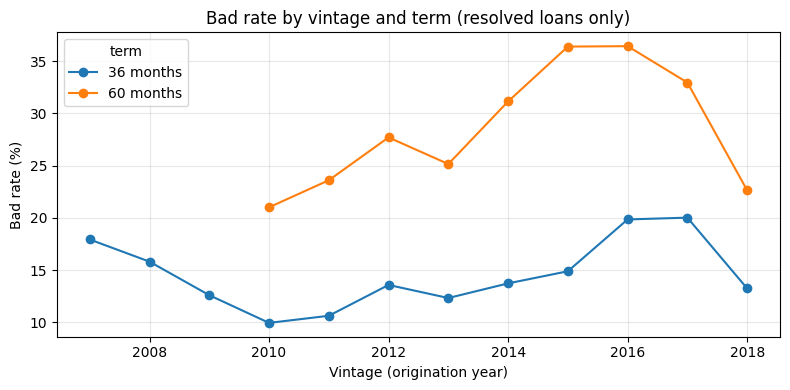


Development (2012, 2014): 306,462 loans | Test 2015: 283,026 loans
Baseline bad rate (development): 13.25%
Bad rate in the 2015 test vintage:   14.89%

Bad rate by vintage with Wilson 95% CI:
 vintage  loans  bad_rate_pct  ci95_low_pct  ci95_high_pct
    2012  43470         13.58         13.26          13.90
    2013 100422         12.33         12.12          12.53
    2014 162570         13.73         13.56          13.89
    2015 283026         14.89         14.76          15.02

Chi-square homogeneity across development vintages: chi2=110.8, dof=2, p=8.631e-25


In [ ]:
# Goal: define bad/good, show which vintages are usable, and measure the baseline risk.

# ---- Dates and keys ----------------------------------------------------------
# Dates are text like "Dec-2015"; convert so we can extract years and compute differences.
data["issue_d"] = pd.to_datetime(data["issue_d"], format="%b-%Y")
data["earliest_cr_line"] = pd.to_datetime(data["earliest_cr_line"], format="%b-%Y")
data["vintage"] = data["issue_d"].dt.year                  # vintage = year of origination
data["term"] = data["term"].astype(str).str.strip()        # raw values have a leading space (" 36 months")

# ---- Target ------------------------------------------------------------------
# resolved: the loan has a final outcome. Active loans (Current, Late...) do not, so they
# cannot be labelled good or bad yet.
data["resolved"] = data["loan_status"].isin(BAD_STATUS + GOOD_STATUS)
data["bad"] = data["loan_status"].isin(BAD_STATUS).astype(int)   # 1 = bad, 0 = good

# Transparency: statuses that fall in the development window but are left out of the population.
window = data[(data["term"] == TARGET_TERM) & data["vintage"].between(DEV_YEARS[0], TEST_YEAR)]
print("\nLoans in the 2012-2015, 36-month window by status (non-resolved ones are excluded):")
print(window["loan_status"].value_counts())

# ---- Bad rate by vintage and term -------------------------------------------
# pct_resolved shows maturity: a low value means many loans have no final outcome yet,
# so that vintage's bad rate is unreliable (right-censoring).
resolved_only = data[data["resolved"]]                     # only resolved loans enter the bad rate
keys = ["term", "vintage"]
vintage_table = pd.DataFrame({
    "loans": data.groupby(keys).size(),                                    # all loans in the cell
    "pct_resolved": (data.groupby(keys)["resolved"].mean() * 100).round(1),  # maturity indicator
    "resolved_loans": resolved_only.groupby(keys).size(),                  # loans with outcome
    "bad_rate_pct": (resolved_only.groupby(keys)["bad"].mean() * 100).round(2),
})
print("\nBad rate by term and vintage:")
print(vintage_table.to_string())

# Chart: bad rate by vintage, one line per term.
rates = vintage_table["bad_rate_pct"].unstack("term")      # rows = vintage, columns = term
ax = rates.plot(marker="o", figsize=(8, 4))
ax.set_title("Bad rate by vintage and term (resolved loans only)")
ax.set_xlabel("Vintage (origination year)")
ax.set_ylabel("Bad rate (%)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Population, development and test sets ----------------------------------
pop = data[(data["term"] == TARGET_TERM) & data["resolved"]].copy()   # 36-month resolved loans
dev = pop[pop["vintage"].between(DEV_YEARS[0], DEV_YEARS[1])].copy()  # development: 2012-2014
test = pop[pop["vintage"] == TEST_YEAR].copy()                        # out-of-time test: 2015
print(f"\nDevelopment {DEV_YEARS}: {len(dev):,} loans | Test {TEST_YEAR}: {len(test):,} loans")

# ---- Baseline risk -----------------------------------------------------------
# Baseline = bad rate if we approved EVERYONE. The model and the cut-off must beat it.
baseline_dev = dev["bad"].mean()
baseline_test = test["bad"].mean()
print(f"Baseline bad rate (development): {baseline_dev:.2%}")
print(f"Bad rate in the {TEST_YEAR} test vintage:   {baseline_test:.2%}")

# ---- Stability across vintages ----------------------------------------------
# Wilson 95% CI of the bad rate per vintage: do the intervals overlap?
rows = []
for v in range(DEV_YEARS[0], TEST_YEAR + 1):
    sub = pop[pop["vintage"] == v]
    n, k = len(sub), int(sub["bad"].sum())                 # number of loans and number of bad loans
    if n == 0:
        continue
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    rows.append({"vintage": v, "loans": n, "bad_rate_pct": 100 * k / n,
                 "ci95_low_pct": 100 * lo, "ci95_high_pct": 100 * hi})
print("\nBad rate by vintage with Wilson 95% CI:")
print(pd.DataFrame(rows).round(2).to_string(index=False))

# Chi-square test of homogeneity across the DEVELOPMENT vintages.
# H0: the bad rate is the same in every vintage. With very large samples H0 is almost always
# rejected, so read the size of the gaps in the table above, not only the p-value.
chi2, p_value, dof, _ = chi2_contingency(pd.crosstab(dev["vintage"], dev["bad"]))
print(f"\nChi-square homogeneity across development vintages: chi2={chi2:.1f}, dof={dof}, p={p_value:.4g}")

In [ ]:
# Goal: keep only variables that exist consistently across all vintages we use.

def engineer(df):
    """Create model-ready variables from raw columns. Uses NO fitted parameters, so there is no leakage."""
    out = df.copy()                                        # never modify the caller's table
    # emp_length: text such as "10+ years" or "< 1 year" -> number of years.
    el = out["emp_length"].astype("string")                # nullable text type keeps missing values as NA
    years = pd.to_numeric(el.str.extract(r"(\d+)")[0], errors="coerce").astype(float)  # first number in the text
    out["emp_length_years"] = years.where(~el.str.startswith("<", na=False), 0.0)      # "< 1 year" -> 0
    # Age of credit history at application, in years (more informative than the raw date).
    out["credit_history_years"] = (out["issue_d"] - out["earliest_cr_line"]).dt.days / 365.25
    return out


NUMERIC_CANDIDATES = [
    "loan_amnt", "annual_inc", "dti", "delinq_2yrs", "fico_range_low", "inq_last_6mths",
    "mths_since_last_delinq", "mths_since_last_record", "open_acc", "pub_rec", "revol_bal",
    "revol_util", "total_acc", "mort_acc", "pub_rec_bankruptcies", "tot_cur_bal",
    "total_rev_hi_lim", "bc_util", "bc_open_to_buy", "acc_open_past_24mths",
    "num_tl_op_past_12m", "pct_tl_nvr_dlq", "emp_length_years", "credit_history_years",
]
CATEGORICAL_CANDIDATES = ["home_ownership", "verification_status", "purpose"]
# Excluded a priori and why:
#   fico_range_high  identical information to fico_range_low (high = low + 4)
#   addr_state       fair-lending risk (geographic proxy) and ~50 levels inflate IV
#   term, application_type  constant in this population (checked below)
#   earliest_cr_line, emp_length  replaced by their numeric versions above
#   BENCHMARK and OUTCOME columns  circularity / leakage
ALL_CANDIDATES = NUMERIC_CANDIDATES + CATEGORICAL_CANDIDATES

pop_eng = engineer(pop)                                    # apply feature engineering to the population
dev_eng = pop_eng[pop_eng["vintage"].between(DEV_YEARS[0], DEV_YEARS[1])].copy()
test_eng = pop_eng[pop_eng["vintage"] == TEST_YEAR].copy()

# Evidence that fico_range_low and fico_range_high are redundant.
print("\nSpearman(fico_range_low, fico_range_high) =",
      round(dev_eng["fico_range_low"].corr(dev_eng["fico_range_high"], method="spearman"), 4))

# Constant variables in the development set (no information): report them.
constants = [c for c in ["term", "application_type"] if dev_eng[c].nunique(dropna=True) <= 1]
print("Constant in the development set (excluded):", constants)

# application_type is constant in development, so the model cannot learn about joint applications.
# If joint applications appear in the test vintage, the test population differs from the training one.
in_window = pop_eng[pop_eng["vintage"].between(DEV_YEARS[0], TEST_YEAR)]
print("\nApplication type mix by vintage (share of loans):")
print(pd.crosstab(in_window["vintage"], in_window["application_type"], normalize="index").round(4).to_string())

# ---- Missing % by vintage ----------------------------------------------------
# Some bureau variables were only collected from certain dates, so they can be 100% missing
# in early vintages. If a variable is missing for whole vintages, median imputation would
# turn it into a "vintage detector" instead of a risk measure.
missing_by_vintage = (pop_eng.loc[pop_eng["vintage"] <= TEST_YEAR, ALL_CANDIDATES]
                      .isna().groupby(pop_eng.loc[pop_eng["vintage"] <= TEST_YEAR, "vintage"])
                      .mean() * 100).round(1).T            # rows = variables, columns = vintages
print("\nMissing % by vintage (36-month resolved loans):")
print(missing_by_vintage.to_string())

# Eligibility rule: <= MISSING_MAX missing in EVERY vintage of the development+test window.
window_missing = missing_by_vintage.loc[:, DEV_YEARS[0]:TEST_YEAR]    # columns 2012..2015
worst_missing = window_missing.max(axis=1)                 # worst vintage for each variable
eligible = worst_missing[worst_missing <= MISSING_MAX * 100].index.tolist()
excluded_missing = worst_missing[worst_missing > MISSING_MAX * 100]
print(f"\nExcluded for missing > {MISSING_MAX:.0%} in some vintage:")
print(excluded_missing.round(1).to_string())
# Note: mths_since_last_delinq / mths_since_last_record are structurally empty (never happened).
# A proper treatment needs a dedicated "never" category (WoE with a MISSING bin); out of scope here.

eligible_num = [c for c in NUMERIC_CANDIDATES if c in eligible]
eligible_cat = [c for c in CATEGORICAL_CANDIDATES if c in eligible]

# ---- Does missingness carry risk information? -------------------------------
# For eligible variables that still have some missing values, compare the bad rate of
# loans with the value missing versus present. Large gaps = informative missingness.
rows = []
for c in eligible_num + eligible_cat:
    is_missing = dev_eng[c].isna()
    if is_missing.sum() >= 50:                             # skip cells too small to interpret
        rows.append({"variable": c, "n_missing": int(is_missing.sum()),
                     "bad_rate_missing_pct": 100 * dev_eng.loc[is_missing, "bad"].mean(),
                     "bad_rate_present_pct": 100 * dev_eng.loc[~is_missing, "bad"].mean()})
print("\nBad rate when the value is missing vs present (development):")
print(pd.DataFrame(rows).round(2).to_string(index=False) if rows else "No eligible variable has enough missing values to test.")


Spearman(fico_range_low, fico_range_high) = 1.0
Constant in the development set (excluded): ['term', 'application_type']

Application type mix by vintage (share of loans):
application_type  Individual  Joint App
vintage                                
2012                  1.0000     0.0000
2013                  1.0000     0.0000
2014                  1.0000     0.0000
2015                  0.9992     0.0008

Missing % by vintage (36-month resolved loans):
vintage                  2007   2008   2009   2010   2011  2012  2013  2014  2015
loan_amnt                 0.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0   0.0
annual_inc                0.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0   0.0
dti                       0.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0   0.0
delinq_2yrs               0.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0   0.0
fico_range_low            0.0    0.0    0.0    0.0    0.0   0.0   0.0   0.0   0.0
inq_last_6mths            0.0    0.0    0.0   

In [ ]:
# Everything here is computed on the DEVELOPMENT set only; the test set is never used to choose variables.

def woe_table(x, y, bins=IV_BINS):
    """Weight of Evidence table for one variable.
    Numeric variables are cut into quantile bins; missing values form their own 'MISSING' bin;
    categorical and low-cardinality variables use their own values as groups."""
    if pd.api.types.is_numeric_dtype(x) and x.dropna().nunique() > bins:
        grp = pd.Series("MISSING", index=x.index, dtype=object)      # start with every row as MISSING
        valid = x.notna()                                            # rows with a value
        ids = pd.qcut(x[valid], q=bins, labels=False, duplicates="drop")   # quantile bin id 0..k-1
        grp.loc[valid] = ids.astype(int).astype(str).str.zfill(2).values   # zero-padded id keeps bins sorted
    else:
        grp = x.astype(object).where(x.notna(), "MISSING").astype(str)     # groups = distinct values
    tab = pd.DataFrame({"grp": grp.values, "bad": y.values})        # pair each group with its outcome
    t = tab.groupby("grp")["bad"].agg(total="count", bad="sum")     # loans and bad loans per group
    t["good"] = t["total"] - t["bad"]
    k = len(t)                                                       # number of groups
    # Add 0.5 to every cell so empty groups do not produce log(0) (standard adjustment).
    pct_bad = (t["bad"] + 0.5) / (t["bad"].sum() + 0.5 * k)          # share of all bads in the group
    pct_good = (t["good"] + 0.5) / (t["good"].sum() + 0.5 * k)       # share of all goods in the group
    t["woe"] = np.log(pct_good / pct_bad)                            # >0 safer than average, <0 riskier
    t["iv"] = (pct_good - pct_bad) * t["woe"]                        # contribution of the group to IV
    return t


def iv_strength(iv):
    """Translate an IV value into the usual verbal scale."""
    if iv < 0.02:
        return "useless (<0.02)"
    if iv < 0.10:
        return "weak (0.02-0.10)"
    if iv < 0.30:
        return "medium (0.10-0.30)"
    if iv <= IV_MAX:
        return "strong (0.30-0.50)"
    return "suspicious (>0.50)"


# ---- Step 4.1: Information Value ranking ------------------------------------
iv_rows = []
for c in eligible_num + eligible_cat:
    iv = woe_table(dev_eng[c], dev_eng["bad"])["iv"].sum()           # total IV = sum over groups
    iv_rows.append({"variable": c, "type": "numeric" if c in eligible_num else "categorical",
                    "iv": round(iv, 4), "strength": iv_strength(iv)})
iv_table = pd.DataFrame(iv_rows).sort_values("iv", ascending=False).reset_index(drop=True)
print("\nInformation Value ranking (development set):")
print(iv_table.to_string())

suspicious = iv_table.loc[iv_table["iv"] > IV_MAX, "variable"].tolist()
if suspicious:
    print("\nWARNING: IV above", IV_MAX, "-> check for leakage before using:", suspicious)
usable = iv_table[(iv_table["iv"] >= IV_MIN) & (iv_table["iv"] <= IV_MAX)]   # keep predictive, non-suspicious
usable_num = [c for c in usable["variable"] if c in eligible_num]            # already sorted by IV (desc)
usable_cat = [c for c in usable["variable"] if c in eligible_cat]

# ---- Step 4.2: remove redundant numeric variables (Spearman) ----------------
# Greedy rule: walk down the IV ranking; keep a variable only if it is not highly correlated
# with one already kept. The stronger variable (higher IV) always wins.
corr = dev_eng[usable_num].corr(method="spearman")                   # rank correlation, pairwise-complete
kept_num, dropped_corr = [], []
for c in usable_num:
    partner = next((k for k in kept_num if abs(corr.loc[c, k]) >= CORR_MAX), None)   # first conflicting kept variable
    if partner is None:
        kept_num.append(c)
    else:
        dropped_corr.append((c, partner, round(corr.loc[c, partner], 3)))
print("\nDropped for redundancy (variable, kept partner, Spearman):", dropped_corr)

# ---- Step 4.3: multicollinearity (VIF), removing the worst offender each round ---
# VIF is computed on the preprocessed numeric matrix (imputed and standardised on train), and
# on a sample for speed (VIF describes the correlation structure, which a sample reproduces).

class Preprocessor:
    """Learns preprocessing parameters on the development set and applies them unchanged to any other set.
    Fitting on development only and re-using the parameters on test is what avoids leakage.
    Numeric steps: winsorise -> log1p if skewed -> median imputation -> standardisation.
    Categorical steps: pool rare levels into RARE -> one-hot encoding (most frequent level = reference)."""

    def __init__(self, numeric, categorical):
        self.numeric = list(numeric)            # numeric variables to process
        self.categorical = list(categorical)    # categorical variables to process
        self.params = {}                        # learned numeric parameters
        self.keep_levels = {}                   # categories frequent enough to keep (per variable)
        self.dummy_levels = {}                  # categories that get a dummy column (per variable)
        self.reference = {}                     # reference category (per variable)

    def fit(self, df):
        for c in self.numeric:
            s = df[c].astype(float)                                   # work on floats
            lo, hi = s.quantile(WINSOR[0]), s.quantile(WINSOR[1])     # winsorisation limits from train
            s = s.clip(lo, hi)                                        # cap outliers
            use_log = bool(s.min() >= 0 and s.skew() > SKEW_MAX)     # log only for non-negative, right-skewed
            if use_log:
                s = np.log1p(s)                                       # log(1 + x), safe at zero
            median = s.median()                                       # imputation value
            s = s.fillna(median)                                      # fill missing values
            std = s.std()
            self.params[c] = {"lo": lo, "hi": hi, "log": use_log, "median": median,
                              "mean": s.mean(), "std": std if std > 0 else 1.0}   # guard against zero variance
        for c in self.categorical:
            s = df[c].astype(object).where(df[c].notna(), "MISSING")  # missing becomes its own category
            freq = s.value_counts(normalize=True)                     # share of each category
            keep = freq[freq >= RARE_LEVEL].index.tolist()            # categories above the rarity threshold
            grouped = s.where(s.isin(keep), "RARE")                   # rare ones -> RARE
            counts = grouped.value_counts()                           # sorted by frequency
            self.keep_levels[c] = keep
            self.reference[c] = counts.index[0]                       # most frequent level is the baseline
            self.dummy_levels[c] = [lvl for lvl in counts.index if lvl != counts.index[0]]
        return self

    def transform(self, df):
        out = pd.DataFrame(index=df.index)                            # result keeps the original row index
        for c in self.numeric:
            p = self.params[c]
            s = df[c].astype(float).clip(p["lo"], p["hi"])            # same caps as in training
            if p["log"]:
                s = np.log1p(s)                                       # same transform as in training
            s = s.fillna(p["median"])                                 # same imputation value
            out[c] = (s - p["mean"]) / p["std"]                       # same standardisation
        for c in self.categorical:
            s = df[c].astype(object).where(df[c].notna(), "MISSING")
            s = s.where(s.isin(self.keep_levels[c]), "RARE")          # unseen/rare levels -> RARE
            for lvl in self.dummy_levels[c]:
                out[f"{c}={lvl}"] = (s == lvl).astype(float)          # 1 if the loan has this category
        return out


vif_sample = dev_eng.sample(min(len(dev_eng), 150_000), random_state=RANDOM_STATE)   # sample for speed
while True:
    X_vif = Preprocessor(kept_num, []).fit(dev_eng).transform(vif_sample)          # numeric matrix, imputed + standardised
    X_vif = sm.add_constant(X_vif, has_constant="add")                              # VIF needs the intercept column
    vifs = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                     index=kept_num)                                                # skip column 0 (the constant)
    worst = vifs.idxmax()                                                           # variable with the highest VIF
    if vifs[worst] <= VIF_MAX or len(kept_num) <= 1:
        break                                                                       # all VIFs acceptable
    print(f"Removing {worst} (VIF = {vifs[worst]:.2f})")
    kept_num.remove(worst)                                                          # drop it and recompute

print("\nFinal VIFs:")
print(vifs.round(2).sort_values(ascending=False).to_string())

final_num = kept_num                         # numeric variables in the model
final_cat = usable_cat                       # categorical variables in the model
print("\nFinal numeric variables:", final_num)
print("Final categorical variables:", final_cat)


Information Value ranking (development set):
                variable         type      iv            strength
0         fico_range_low      numeric  0.1320  medium (0.10-0.30)
1             annual_inc      numeric  0.0870    weak (0.02-0.10)
2                    dti      numeric  0.0475    weak (0.02-0.10)
3         home_ownership  categorical  0.0390    weak (0.02-0.10)
4         inq_last_6mths      numeric  0.0286    weak (0.02-0.10)
5                purpose  categorical  0.0226    weak (0.02-0.10)
6             revol_util      numeric  0.0207    weak (0.02-0.10)
7   credit_history_years      numeric  0.0199     useless (<0.02)
8              revol_bal      numeric  0.0178     useless (<0.02)
9              total_acc      numeric  0.0093     useless (<0.02)
10   verification_status  categorical  0.0092     useless (<0.02)
11             loan_amnt      numeric  0.0078     useless (<0.02)
12  pub_rec_bankruptcies      numeric  0.0019     useless (<0.02)
13           delinq_2yrs      

In [ ]:
# statsmodels (not scikit-learn) because it gives standard errors, p-values and confidence
# intervals. No penalty and no class weights: we want unbiased coefficients and honest PDs.

pre = Preprocessor(final_num, final_cat).fit(dev_eng)          # learn preprocessing on development only
X_dev = pre.transform(dev_eng)                                 # development design matrix
X_test = pre.transform(test_eng)                               # test matrix, SAME parameters
y_dev = dev_eng["bad"].to_numpy()                              # development outcome (0/1)
y_test = test_eng["bad"].to_numpy()                            # test outcome (0/1)

logit = sm.Logit(y_dev, sm.add_constant(X_dev, has_constant="add"))   # intercept + predictors
result = logit.fit(disp=0, maxiter=200)                        # maximum likelihood; disp=0 silences iterations
print("\nConverged:", result.mle_retvals.get("converged"))     # assumption 9: convergence / no perfect separation

# Events per variable (assumption 8): bad loans divided by estimated parameters.
epv = y_dev.sum() / len(result.params)
print(f"Events per parameter (EPV): {epv:,.0f}  (rule of thumb: >= 10)")

# Coefficient table. Variables are standardised, so odds ratios are per +1 standard deviation
# (for dummies: versus the reference category).
ci = result.conf_int()                                          # 95% confidence intervals of the coefficients
coef_table = pd.DataFrame({
    "coef": result.params,
    "std_err": result.bse,
    "z": result.tvalues,
    "p_value": result.pvalues,
    "odds_ratio": np.exp(result.params),                        # exp(coef): multiplicative change in odds
    "or_ci_low": np.exp(ci[0]),
    "or_ci_high": np.exp(ci[1]),
})
print("\nLogit coefficients (sorted by |z|):")
print(coef_table.reindex(coef_table["z"].abs().sort_values(ascending=False).index).round(4).to_string())

# Predicted PDs for development and test.
pd_dev = np.asarray(result.predict(sm.add_constant(X_dev, has_constant="add")))
pd_test = np.asarray(result.predict(sm.add_constant(X_test, has_constant="add")))
dev_eng["pd"] = pd_dev                                        # keep PDs next to the loans (used in sections 6 and 9)
test_eng["pd"] = pd_test

# ---- Linearity in the log-odds (assumption 6) --------------------------------
# For each numeric variable: bad rate by decile of the RAW variable. A roughly monotonic
# pattern supports using it linearly; a U-shape or plateaus would call for binning (WoE).
def decile_table(x, y, q=IV_BINS):
    valid = x.notna()
    bucket = pd.qcut(x[valid], q=q, labels=False, duplicates="drop")        # decile id per loan
    t = pd.DataFrame({"x": x[valid], "bad": y[valid], "bucket": bucket})
    return t.groupby("bucket").agg(x_min=("x", "min"), x_max=("x", "max"),
                                   n=("bad", "size"), bad_rate=("bad", "mean"))


print("\nLinearity check: Spearman between decile order and bad rate (+1/-1 = monotonic):")
for c in final_num:
    g = decile_table(dev_eng[c], dev_eng["bad"])
    mono = g["bad_rate"].corr(pd.Series(g.index, index=g.index), method="spearman")
    print(f"  {c:<25} monotonicity = {mono:+.2f}   bad rate from {g['bad_rate'].iloc[0]:.1%} to {g['bad_rate'].iloc[-1]:.1%}")


Converged: True
Events per parameter (EPV): 2,388  (rule of thumb: >= 10)

Logit coefficients (sorted by |z|):
                            coef  std_err         z  p_value  odds_ratio  or_ci_low  or_ci_high
const                    -2.0738   0.0099 -209.2603   0.0000      0.1257     0.1233      0.1282
fico_range_low           -0.3214   0.0072  -44.8917   0.0000      0.7251     0.7150      0.7354
annual_inc               -0.2099   0.0061  -34.3448   0.0000      0.8107     0.8010      0.8204
inq_last_6mths            0.1668   0.0054   30.9019   0.0000      1.1815     1.1691      1.1941
dti                       0.1566   0.0056   27.7821   0.0000      1.1695     1.1566      1.1825
home_ownership=RENT       0.2423   0.0122   19.9151   0.0000      1.2742     1.2441      1.3049
purpose=small_business    0.7757   0.0412   18.8397   0.0000      2.1720     2.0036      2.3545
purpose=credit_card      -0.2152   0.0136  -15.7729   0.0000      0.8063     0.7851      0.8282
revol_util              


Discrimination and calibration-in-the-large:
                             AUC    Gini      KS  Bad rate  Mean PD
Development (2012, 2014)  0.6457  0.2915  0.2115    0.1325   0.1325
Test 2015                 0.6479  0.2958  0.2116    0.1489   0.1316

Test AUC = 0.6479  (95% bootstrap CI 0.6453 - 0.6505); Gini = 0.2958
Brier score (test) = 0.1228 | reference (constant baseline PD) = 0.1270
Calibration intercept = +0.141 (ideal 0) | slope = 0.996 (ideal 1)

Calibration by PD decile (test):
           loans  mean_pd  observed_bad_rate
pd_decile                                   
1          28303   0.0441             0.0443
2          28303   0.0693             0.0762
3          28302   0.0865             0.1009
4          28303   0.1017             0.1184
5          28302   0.1164             0.1374
6          28303   0.1317             0.1531
7          28302   0.1484             0.1739
8          28303   0.1684             0.1920
9          28302   0.1954             0.2193
10         2

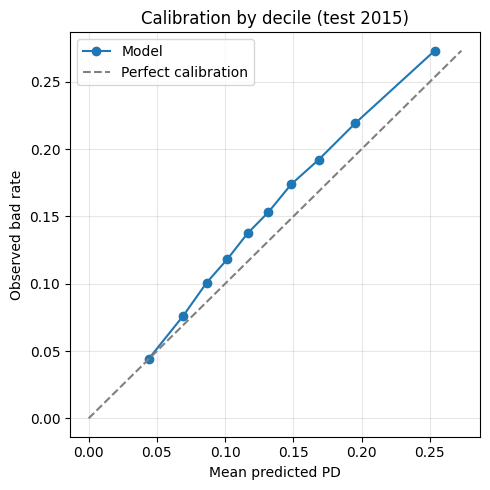


Drift by vintage (development vintages are in-sample, so their gap is ~0 by construction):
          loans  observed_bad_rate  mean_pd  mean_int_rate  observed_minus_pd_pp
vintage                                                                         
2012      43470             0.1358   0.1305        12.6264                0.5314
2013     100422             0.1233   0.1297        13.3670               -0.6411
2014     162570             0.1373   0.1347        12.4654                0.2539
2015     283026             0.1489   0.1316        11.2765                1.7303

Benchmark against Lending Club's own risk output (test):
                                         score  AUC_test  Gini_test  KS_test
                            Our scorecard (PD)    0.6479     0.2958   0.2116
                         Lending Club int_rate    0.6784     0.3569   0.2621
                 Lending Club grade (A=1..G=7)    0.6675     0.3351   0.2616
Our PD + Lending Club int_rate (fitted on dev)    0.6818

In [ ]:
# Discrimination (AUC, Gini, KS) and calibration, on development and on the 2015 test set.

def ks_stat(y, p):
    """KS = largest gap between the PD distributions of bad and good loans."""
    return ks_2samp(p[y == 1], p[y == 0]).statistic


auc_dev, auc_test = roc_auc_score(y_dev, pd_dev), roc_auc_score(y_test, pd_test)
metrics = pd.DataFrame({
    "AUC": [auc_dev, auc_test],
    "Gini": [2 * auc_dev - 1, 2 * auc_test - 1],               # Gini = 2 x AUC - 1
    "KS": [ks_stat(y_dev, pd_dev), ks_stat(y_test, pd_test)],
    "Bad rate": [y_dev.mean(), y_test.mean()],
    "Mean PD": [pd_dev.mean(), pd_test.mean()],
}, index=[f"Development {DEV_YEARS}", f"Test {TEST_YEAR}"])
print("\nDiscrimination and calibration-in-the-large:")
print(metrics.round(4).to_string())
# A large drop from development to test would signal overfitting or a change in the population.

# Bootstrap confidence interval for the test AUC.
rng = np.random.default_rng(RANDOM_STATE)                      # reproducible random numbers
boot = []
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_test), len(y_test))            # resample test loans with replacement
    if y_test[idx].min() == y_test[idx].max():                 # AUC needs both classes
        continue
    boot.append(roc_auc_score(y_test[idx], pd_test[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nTest AUC = {auc_test:.4f}  (95% bootstrap CI {lo:.4f} - {hi:.4f}); Gini = {2 * auc_test - 1:.4f}")

# ---- Calibration -------------------------------------------------------------
# Brier score: mean squared error of the PDs (compare with the no-skill score of predicting the base rate).
brier = brier_score_loss(y_test, pd_test)
brier_ref = brier_score_loss(y_test, np.full(len(y_test), y_dev.mean()))   # always predict the development bad rate
print(f"Brier score (test) = {brier:.4f} | reference (constant baseline PD) = {brier_ref:.4f}")

# Calibration slope and intercept: regress the outcome on logit(PD). Ideal: intercept 0, slope 1.
# slope < 1 means PDs are too spread out (overconfident); slope > 1 means too compressed.
p_clip = np.clip(pd_test, 1e-6, 1 - 1e-6)                      # avoid log(0)
logit_pd = np.log(p_clip / (1 - p_clip))                       # PD on the log-odds scale
cal_fit = sm.Logit(y_test, sm.add_constant(pd.DataFrame({"logit_pd": logit_pd}))).fit(disp=0)
print(f"Calibration intercept = {cal_fit.params.iloc[0]:+.3f} (ideal 0) | slope = {cal_fit.params.iloc[1]:.3f} (ideal 1)")

# Calibration table by PD decile on the test set.
test_eng["pd_decile"] = pd.qcut(test_eng["pd"], 10, labels=False, duplicates="drop") + 1   # 1 = safest
cal_table = test_eng.groupby("pd_decile").agg(loans=("bad", "size"), mean_pd=("pd", "mean"), observed_bad_rate=("bad", "mean"))
print("\nCalibration by PD decile (test):")
print(cal_table.round(4).to_string())

plt.figure(figsize=(5, 5))
plt.plot(cal_table["mean_pd"], cal_table["observed_bad_rate"], marker="o", label="Model")
top = float(max(cal_table["mean_pd"].max(), cal_table["observed_bad_rate"].max()))
plt.plot([0, top], [0, top], "--", color="grey", label="Perfect calibration")
plt.xlabel("Mean predicted PD")
plt.ylabel("Observed bad rate")
plt.title(f"Calibration by decile (test {TEST_YEAR})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- Drift: did the applicants change, or did the risk of the same applicants change? ----
# Covariate shift: mean PD changes (different mix of applicants).
# Concept drift:   mean PD is stable but the observed bad rate moves (same profile, higher risk).
# mean_int_rate is Lending Club's own pricing of risk: if it rises while our mean PD does not,
# Lending Club saw risk (through variables we do not use) that our model cannot see.
both = pd.concat([dev_eng[["vintage", "bad", "pd", "int_rate"]], test_eng[["vintage", "bad", "pd", "int_rate"]]])
drift = both.groupby("vintage").agg(loans=("bad", "size"), observed_bad_rate=("bad", "mean"),
                                    mean_pd=("pd", "mean"), mean_int_rate=("int_rate", "mean"))
drift["observed_minus_pd_pp"] = (drift["observed_bad_rate"] - drift["mean_pd"]) * 100
print("\nDrift by vintage (development vintages are in-sample, so their gap is ~0 by construction):")
print(drift.round(4).to_string())

# ---- Benchmark: Lending Club's own risk output on the same test loans ----------
# Without a reference we cannot say whether a Gini of ~0.30 is weak or normal for this data.
# int_rate and grade are NOT model inputs; here they are only compared with our PD.
GRADE_NUM = {g: i for i, g in enumerate("ABCDEFG", start=1)}   # A (safest) = 1 ... G (riskiest) = 7
dev_eng["grade_num"] = dev_eng["grade"].astype(str).map(GRADE_NUM)
test_eng["grade_num"] = test_eng["grade"].astype(str).map(GRADE_NUM)

scores_test = {
    "Our scorecard (PD)": pd_test,
    "Lending Club int_rate": test_eng["int_rate"].to_numpy(),
    "Lending Club grade (A=1..G=7)": test_eng["grade_num"].to_numpy(),
}
rows = []
for name, s in scores_test.items():
    a = roc_auc_score(y_test, s)                               # higher score = riskier for all three
    rows.append({"score": name, "AUC_test": a, "Gini_test": 2 * a - 1, "KS_test": ks_stat(y_test, np.asarray(s, dtype=float))})

# Incremental information: combine our PD (on the log-odds scale) with int_rate, fitted on development.
def to_logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)    # avoid log(0)
    return np.log(p / (1 - p))

comb_dev = pd.DataFrame({"logit_pd": to_logit(pd_dev), "int_rate": dev_eng["int_rate"].to_numpy()})
comb_test = pd.DataFrame({"logit_pd": to_logit(pd_test), "int_rate": test_eng["int_rate"].to_numpy()})
comb = sm.Logit(y_dev, sm.add_constant(comb_dev)).fit(disp=0)
p_comb = np.asarray(comb.predict(sm.add_constant(comb_test, has_constant="add")))
a = roc_auc_score(y_test, p_comb)
rows.append({"score": "Our PD + Lending Club int_rate (fitted on dev)", "AUC_test": a,
             "Gini_test": 2 * a - 1, "KS_test": ks_stat(y_test, p_comb)})
print("\nBenchmark against Lending Club's own risk output (test):")
print(pd.DataFrame(rows).round(4).to_string(index=False))
# Reading guide: if the combined score beats int_rate alone, our variables add information beyond
# Lending Club's pricing; if int_rate alone beats ours, Lending Club used information we do not have.

In [ ]:
# Write the narrative answer in the notebook AFTER reading the tables above. Rules:
#   - Use the sign and size of the odds ratios (risk increases when OR > 1, decreases when OR < 1).
#   - Describe ASSOCIATIONS ("higher dti is associated with higher default risk"), not causes.
#   - Quote Gini, KS and calibration with their intervals, and compare with the baseline bad rate.
drivers = coef_table.drop(index="const")
drivers = drivers.reindex(drivers["z"].abs().sort_values(ascending=False).index)   # strongest first
print("\nRisk drivers, strongest to weakest (OR per +1 SD):")
for name, row in drivers.iterrows():
    direction = "raises" if row["odds_ratio"] > 1 else "lowers"
    print(f"  {name:<30} OR = {row['odds_ratio']:.2f}  ({direction} default odds)   p = {row['p_value']:.3g}")


Risk drivers, strongest to weakest (OR per +1 SD):
  fico_range_low                 OR = 0.73  (lowers default odds)   p = 0
  annual_inc                     OR = 0.81  (lowers default odds)   p = 1.69e-258
  inq_last_6mths                 OR = 1.18  (raises default odds)   p = 1.13e-209
  dti                            OR = 1.17  (raises default odds)   p = 7.14e-170
  home_ownership=RENT            OR = 1.27  (raises default odds)   p = 3.01e-88
  purpose=small_business         OR = 2.17  (raises default odds)   p = 3.57e-79
  purpose=credit_card            OR = 0.81  (lowers default odds)   p = 4.78e-56
  revol_util                     OR = 1.04  (raises default odds)   p = 1.84e-11
  home_ownership=OWN             OR = 1.13  (raises default odds)   p = 1.81e-10
  purpose=other                  OR = 1.15  (raises default odds)   p = 1.67e-09
  purpose=medical                OR = 1.28  (raises default odds)   p = 2.71e-07
  purpose=RARE                   OR = 1.19  (raises default o


Approval rate vs bad rate (test 2015, baseline bad rate 14.89%):
 approval_rate  n_approved  pd_cutoff  mean_pd  bad_rate  bad_rate_vs_baseline
          0.10       28303     0.0593   0.0441    0.0443                0.2979
          0.15       42454     0.0696   0.0509    0.0530                0.3560
          0.20       56605     0.0784   0.0567    0.0603                0.4049
          0.25       70756     0.0866   0.0619    0.0673                0.4519
          0.30       84908     0.0943   0.0667    0.0738                0.4958
          0.35       99059     0.1018   0.0711    0.0797                0.5356
          0.40      113210     0.1090   0.0754    0.0849                0.5706
          0.45      127362     0.1164   0.0796    0.0900                0.6047
          0.50      141513     0.1238   0.0836    0.0954                0.6411
          0.55      155664     0.1316   0.0876    0.1003                0.6736
          0.60      169816     0.1397   0.0916    0.1050         

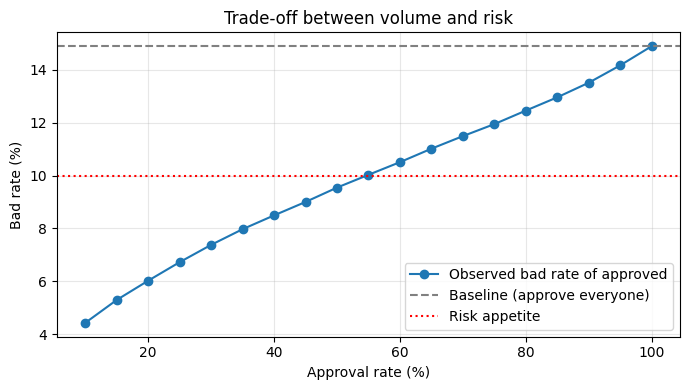

In [ ]:
# Cut-offs are defined by percentiles of the PD ranking (approve the X% safest applicants),
# which stays meaningful whatever the baseline risk is. We report the PD value of each cut-off.
ranked = test_eng.sort_values("pd").reset_index(drop=True)     # safest first
shares = np.round(np.arange(0.10, 1.0001, 0.05), 2)            # approval rates 10%, 15%, ..., 100%

rows = []
for q in shares:
    n_app = int(round(q * len(ranked)))                        # number of approved applicants
    app = ranked.iloc[:n_app]                                  # the n_app lowest-PD applicants
    rows.append({"approval_rate": q, "n_approved": n_app,
                 "pd_cutoff": app["pd"].max(),                 # highest PD still approved
                 "mean_pd": app["pd"].mean(),                  # predicted bad rate of the approved
                 "bad_rate": app["bad"].mean(),                # OBSERVED bad rate of the approved
                 "bad_rate_vs_baseline": app["bad"].mean() / baseline_test})
policy = pd.DataFrame(rows)
print(f"\nApproval rate vs bad rate (test {TEST_YEAR}, baseline bad rate {baseline_test:.2%}):")
print(policy.round(4).to_string(index=False))

# Risk appetite: the largest approval rate whose observed bad rate stays within the ceiling.
within = policy[policy["bad_rate"] <= RISK_APPETITE]
if len(within):
    best_app = within.iloc[-1]
    print(f"\nRisk appetite {RISK_APPETITE:.0%}: approve up to {best_app['approval_rate']:.0%} "
          f"(PD cut-off {best_app['pd_cutoff']:.3f}, bad rate {best_app['bad_rate']:.2%})")
else:
    print(f"\nNo approval rate keeps the bad rate within {RISK_APPETITE:.0%} (baseline {baseline_test:.2%}).")

plt.figure(figsize=(7, 4))
plt.plot(policy["approval_rate"] * 100, policy["bad_rate"] * 100, marker="o", label="Observed bad rate of approved")
plt.axhline(baseline_test * 100, color="grey", linestyle="--", label="Baseline (approve everyone)")
plt.axhline(RISK_APPETITE * 100, color="red", linestyle=":", label="Risk appetite")
plt.xlabel("Approval rate (%)")
plt.ylabel("Bad rate (%)")
plt.title("Trade-off between volume and risk")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Economic parameters measured on outcomes:
  Interest actually earned / contractual (good loans):  dev 0.816 | test 0.802  (assumed in base case: 1.000)
  Net loss rate on defaulted loans (measured LGD):      dev 0.349 | test 0.375  (assumed in base case: 0.650)
  Check total_pymnt - cash_in: mean = 1.53, share of loans with |gap| > 1 = 4.2%

Profit-maximising approval rate by scenario (0% = lending is not profitable at any cut-off):
                   scenario  best_approval_rate  pd_cutoff  bad_rate  expected_profit_M  realised_profit_same_cut_M               verdict
             Base (assumed)                0.70     0.1578    0.1149            38.7740                    -11.9537                      
                 Funding 3%                0.90     0.2138    0.1351           133.8765                     77.5359                      
                 Funding 7%                0.00        NaN       NaN             0.0000                      0.0000 NO PROFITABLE CUT-OFF
          

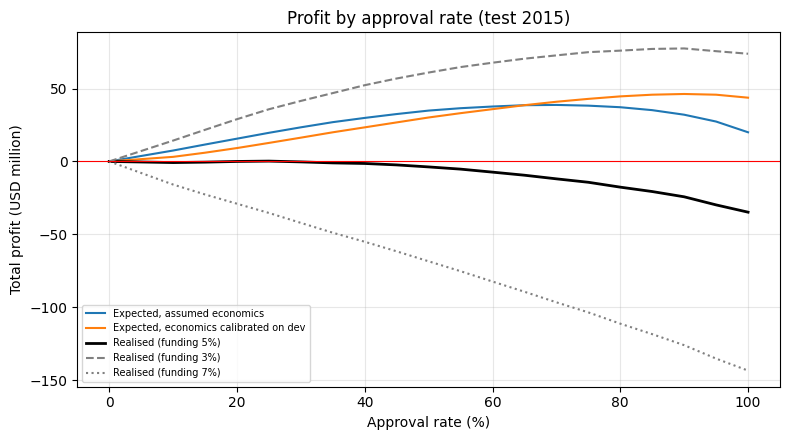


Profit bridge at approval rate 70% - Expected-profit optimum (base):
                                                               USD_million
Expected profit (PD, contractual interest, assumed LGD)              38.77
1) Actual defaults instead of PD (calibration of the level)         -61.97
2) Interest really earned instead of contractual (prepayment)       -80.88
3) Real cash result on defaults instead of assumed LGD               92.12
4) Residual (principal shortfalls on good loans, rounding)           -0.00
Realised profit                                                     -11.95

Profit bridge at approval rate 50% - Largest approval within 10% bad rate:
                                                               USD_million
Expected profit (PD, contractual interest, assumed LGD)              34.89
1) Actual defaults instead of PD (calibration of the level)         -38.53
2) Interest really earned instead of contractual (prepayment)       -59.75
3) Real cash result on defaul

In [ ]:
# Four steps:
#   9.1 Measure the economic parameters on DEVELOPMENT outcomes instead of assuming them.
#   9.2 Profit by approval rate on the test vintage: expected vs realised, with sensitivity.
#   9.3 Why expected and realised differ: the profit bridge.
#   9.4 Policies fixed ex-ante on development, evaluated out of time on the test vintage.

# ---- Building blocks ---------------------------------------------------------
def contractual_interest(df):
    """Interest a loan earns if every instalment is paid on time for the full 36 months."""
    return df["installment"] * 36 - df["loan_amnt"]


def cash_in(df):
    """Cash actually received: principal + interest + recoveries.
    Late fees and collection costs are not loaded, so this is only approximately exact."""
    return df["total_rec_prncp"] + df["total_rec_int"] + df["recoveries"]


def funding_cost(df, funding):
    """Cost of the money lent: annual rate x amount x average life of the funds (years)."""
    return funding * df["loan_amnt"] * AVG_LIFE_YEARS


def expected_profit(df, lgd, funding, pd_mult=1.0, interest_factor=1.0):
    """Expected profit per loan, computed BEFORE the outcome is known:
         (1 - PD) x interest_factor x contractual interest  -  PD x LGD x EAD  -  funding cost
    interest_factor < 1 accounts for prepayment (interest actually earned vs promised).
    Needs a column 'pd' in df."""
    p = np.clip(df["pd"] * pd_mult, 0, 1)                      # (stressed) PD, kept inside [0, 1]
    interest = interest_factor * contractual_interest(df)
    return (1 - p) * interest - p * lgd * df["loan_amnt"] - funding_cost(df, funding)


def realised_profit(df, funding):
    """Realised profit per loan, computed AFTER the outcome: cash received - amount lent - funding cost."""
    return cash_in(df) - df["loan_amnt"] - funding_cost(df, funding)


def totals_at(per_loan_profit, n_list):
    """Total profit if we approve the first n loans (safest first), for each n in n_list.
    A leading 0 makes n = 0 (approve nobody) a valid option with profit 0."""
    cum = np.concatenate([[0.0], per_loan_profit.cumsum().to_numpy()])
    return cum[np.asarray(n_list)]


# ---- 9.1 Economic parameters measured on development ------------------------
good_dev = dev_eng[dev_eng["bad"] == 0]
bad_dev = dev_eng[dev_eng["bad"] == 1]
# phi: share of the contractual interest that good loans really pay (below 1 because of prepayment).
phi_dev = good_dev["total_rec_int"].sum() / contractual_interest(good_dev).sum()
# lam: net loss rate on defaulted loans, after instalments paid before default and recoveries.
lam_dev = (bad_dev["loan_amnt"] - cash_in(bad_dev)).sum() / bad_dev["loan_amnt"].sum()

good_te, bad_te = test_eng[test_eng["bad"] == 0], test_eng[test_eng["bad"] == 1]
phi_te = good_te["total_rec_int"].sum() / contractual_interest(good_te).sum()
lam_te = (bad_te["loan_amnt"] - cash_in(bad_te)).sum() / bad_te["loan_amnt"].sum()
print("\nEconomic parameters measured on outcomes:")
print(f"  Interest actually earned / contractual (good loans):  dev {phi_dev:.3f} | test {phi_te:.3f}  (assumed in base case: 1.000)")
print(f"  Net loss rate on defaulted loans (measured LGD):      dev {lam_dev:.3f} | test {lam_te:.3f}  (assumed in base case: {LGD_BASE:.3f})")

# Diagnostic: total_pymnt should be close to principal + interest + recoveries (the gap = late fees).
gap = test_eng["total_pymnt"] - cash_in(test_eng)
print(f"  Check total_pymnt - cash_in: mean = {gap.mean():.2f}, share of loans with |gap| > 1 = {(gap.abs() > 1).mean():.1%}")

# ---- 9.2 Profit by approval rate on the test vintage ------------------------
ranked = test_eng.sort_values("pd").reset_index(drop=True)     # safest first
shares_ext = np.round(np.concatenate([[0.0], np.arange(0.10, 1.0001, 0.05)]), 2)   # 0% = approve nobody
counts = np.array([int(round(q * len(ranked))) for q in shares_ext])               # approved loans at each rate

# Scenarios: (LGD, funding cost, PD multiplier, interest factor). The first six are assumptions;
# the last two use the parameters measured on development.
scenarios = {
    "Base (assumed)":                  (LGD_BASE, FUNDING_BASE, 1.0, 1.0),
    "Funding 3%":                      (LGD_BASE, 0.03, 1.0, 1.0),
    "Funding 7%":                      (LGD_BASE, 0.07, 1.0, 1.0),
    "LGD 60%":                         (0.60, FUNDING_BASE, 1.0, 1.0),
    "LGD 70%":                         (0.70, FUNDING_BASE, 1.0, 1.0),
    f"PD stress x{PD_STRESS:.1f}":     (LGD_BASE, FUNDING_BASE, PD_STRESS, 1.0),
    "Calibrated on dev":               (lam_dev, FUNDING_BASE, 1.0, phi_dev),
    f"Calibrated + PD stress x{PD_STRESS:.1f}": (lam_dev, FUNDING_BASE, PD_STRESS, phi_dev),
}

rows, exp_curves = [], {}
for name, (lgd, fund, mult, phi) in scenarios.items():
    totals = totals_at(expected_profit(ranked, lgd, fund, mult, phi), counts)      # expected profit at every approval rate
    exp_curves[name] = totals
    i = int(np.argmax(totals))                                                      # best approval rate (0 = approve nobody)
    n_i = counts[i]
    rows.append({
        "scenario": name,
        "best_approval_rate": shares_ext[i],
        "pd_cutoff": ranked["pd"].iloc[n_i - 1] if n_i > 0 else np.nan,
        "bad_rate": ranked["bad"].iloc[:n_i].mean() if n_i > 0 else np.nan,
        "expected_profit_M": totals[i] / 1e6,
        "realised_profit_same_cut_M": totals_at(realised_profit(ranked, fund), counts)[i] / 1e6,
        "verdict": "NO PROFITABLE CUT-OFF" if i == 0 else "",
    })
print("\nProfit-maximising approval rate by scenario (0% = lending is not profitable at any cut-off):")
print(pd.DataFrame(rows).round(4).to_string(index=False))

realised_by_funding = {f: totals_at(realised_profit(ranked, f), counts) for f in (0.03, 0.05, 0.07)}
curve_table = pd.DataFrame({
    "approval_rate": shares_ext,
    "n_approved": counts,
    "expected_base_M": exp_curves["Base (assumed)"] / 1e6,
    "expected_calibrated_M": exp_curves["Calibrated on dev"] / 1e6,
    "realised_fund3_M": realised_by_funding[0.03] / 1e6,
    "realised_fund5_M": realised_by_funding[0.05] / 1e6,
    "realised_fund7_M": realised_by_funding[0.07] / 1e6,
})
print("\nTotal profit by approval rate (USD million, test vintage):")
print(curve_table.round(2).to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(shares_ext * 100, curve_table["expected_base_M"], label="Expected, assumed economics")
plt.plot(shares_ext * 100, curve_table["expected_calibrated_M"], label="Expected, economics calibrated on dev")
plt.plot(shares_ext * 100, curve_table["realised_fund5_M"], color="black", linewidth=2, label="Realised (funding 5%)")
plt.plot(shares_ext * 100, curve_table["realised_fund3_M"], color="grey", linestyle="--", label="Realised (funding 3%)")
plt.plot(shares_ext * 100, curve_table["realised_fund7_M"], color="grey", linestyle=":", label="Realised (funding 7%)")
plt.axhline(0, color="red", linewidth=0.8)
plt.xlabel("Approval rate (%)")
plt.ylabel("Total profit (USD million)")
plt.title(f"Profit by approval rate (test {TEST_YEAR})")
plt.legend(fontsize=7)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ---- 9.3 Profit bridge: why expected and realised profit differ -------------
# Each step replaces ONE assumption by what really happened. Funding cost is the same in the
# expected and the realised formulas, so it cannot explain the gap.
def profit_bridge(app, lgd=LGD_BASE, funding=FUNDING_BASE):
    """Return the bridge from expected to realised profit for a set of approved loans (USD million)."""
    bad = app["bad"]                                                     # actual outcome: 1 = bad
    interest, ead, fund = contractual_interest(app), app["loan_amnt"], funding_cost(app, funding)
    s0 = expected_profit(app, lgd, funding).sum()                       # PD, contractual interest, assumed LGD
    s1 = ((1 - bad) * interest - bad * lgd * ead - fund).sum()          # actual defaults instead of PD
    s2 = ((1 - bad) * app["total_rec_int"] - bad * lgd * ead - fund).sum()   # + interest really earned on good loans
    s3 = ((1 - bad) * app["total_rec_int"] + bad * (cash_in(app) - ead) - fund).sum()   # + real cash result on bad loans
    s4 = realised_profit(app, funding).sum()                            # realised profit
    return pd.DataFrame({"USD_million": [s0 / 1e6, (s1 - s0) / 1e6, (s2 - s1) / 1e6, (s3 - s2) / 1e6,
                                         (s4 - s3) / 1e6, s4 / 1e6]},
                        index=["Expected profit (PD, contractual interest, assumed LGD)",
                               "1) Actual defaults instead of PD (calibration of the level)",
                               "2) Interest really earned instead of contractual (prepayment)",
                               "3) Real cash result on defaults instead of assumed LGD",
                               "4) Residual (principal shortfalls on good loans, rounding)",
                               "Realised profit"]).round(2)


bridge_cuts = {"Expected-profit optimum (base)": shares_ext[int(np.argmax(exp_curves["Base (assumed)"]))]}
if len(within):                                                        # appetite-constrained cut from section 8
    bridge_cuts[f"Largest approval within {RISK_APPETITE:.0%} bad rate"] = best_app["approval_rate"]
for label, share in bridge_cuts.items():
    n_cut = int(round(share * len(ranked)))
    if n_cut == 0:
        continue
    print(f"\nProfit bridge at approval rate {share:.0%} - {label}:")
    print(profit_bridge(ranked.iloc[:n_cut]).to_string())


# ---- 9.4 Policies fixed on development, evaluated out of time ---------------
# A cut-off chosen with the test outcomes would make the test result optimistic. Here every
# policy is defined with development data only and then applied, unchanged, to the test vintage.
dev_ranked = dev_eng.sort_values("pd").reset_index(drop=True)
dev_counts = np.array([int(round(q * len(dev_ranked))) for q in shares_ext])
dev_cum_bad = np.concatenate([[0], dev_ranked["bad"].cumsum().to_numpy()])      # cumulative bad loans, safest first


def evaluate(df, mask):
    """Approval rate, bad rate, mean PD and profit (expected and realised) of the loans selected by mask."""
    app = df[mask]
    if len(app) == 0:
        return {"approval_rate": 0.0, "bad_rate": np.nan, "mean_pd": np.nan, "expected_base_M": 0.0,
                "expected_calibrated_M": 0.0, "realised_M": 0.0}
    return {"approval_rate": len(app) / len(df), "bad_rate": app["bad"].mean(), "mean_pd": app["pd"].mean(),
            "expected_base_M": expected_profit(app, LGD_BASE, FUNDING_BASE).sum() / 1e6,
            "expected_calibrated_M": expected_profit(app, lam_dev, FUNDING_BASE, 1.0, phi_dev).sum() / 1e6,
            "realised_M": realised_profit(app, FUNDING_BASE).sum() / 1e6}


policies = {}                                                          # name -> function(df) returning a mask

# Policy A: largest approval rate whose DEVELOPMENT bad rate stays within the risk appetite.
ok_n = [n for n in dev_counts if n > 0 and dev_cum_bad[n] / n <= RISK_APPETITE]
if ok_n:
    t_A = dev_ranked["pd"].iloc[max(ok_n) - 1]                         # PD threshold fixed on development
    policies[f"A: risk appetite {RISK_APPETITE:.0%} (PD <= {t_A:.3f})"] = lambda df, t=t_A: df["pd"] <= t

# Policy B: approval rate that maximises expected profit on development (assumed economics).
dev_totals = totals_at(expected_profit(dev_ranked, LGD_BASE, FUNDING_BASE), dev_counts)
n_B = dev_counts[int(np.argmax(dev_totals))]
if n_B > 0:
    t_B = dev_ranked["pd"].iloc[n_B - 1]
    policies[f"B: max expected profit, assumed economics (PD <= {t_B:.3f})"] = lambda df, t=t_B: df["pd"] <= t

# Policy C: break-even rule. Approve a loan only if its expected profit, with the economics
# measured on development, is positive. The implied bad rate is the risk appetite the economics justify.
policies["C: break-even rule, economics calibrated on dev"] = (
    lambda df: expected_profit(df, lam_dev, FUNDING_BASE, 1.0, phi_dev) > 0)

rows = []
for name, rule in policies.items():
    for sample_name, df in (("development", dev_eng), (f"test {TEST_YEAR}", test_eng)):
        rows.append({"policy": name, "sample": sample_name, **evaluate(df, rule(df))})
print("\nPolicies fixed on development, evaluated on development and out of time:")
print(pd.DataFrame(rows).round(4).to_string(index=False))
# How to read: the 'test' rows are the honest result. If realised profit is negative there, the
# policy would have lost money even though it looked profitable on paper; compare bad_rate with the
# risk appetite and mean_pd with bad_rate to see how much of the problem is PD under-prediction.

In [ ]:
# 1. Selection bias: only approved loans are observed; conclusions apply to that population
#    (reject inference is not attempted).
# 2. Single credit cycle: 2012-2015 was a benign period; a downturn would raise PDs.
#    The PD stress scenario is a rough proxy, not a forecast.
# 3. Simplified economics: EAD equals the original amount, funding cost is a flat assumption,
#    operating costs, collection costs and late fees are ignored. Prepayment and the net loss
#    on defaults are measured on development vintages and assumed stable afterwards (section 9.1
#    compares them with the test vintage).
# 4. Observations may not be independent (a borrower can hold several loans).
# 5. Structurally missing variables (months since last delinquency / public record) were
#    excluded; a WoE scorecard with a "never" category could recover that information.
# 6. Predictive association is not causation: coefficients describe who tends to default,
#    not why.
# 7. Drift: a model fitted on 2012-2014 can under-predict a later vintage even when it still
#    ranks borrowers well (section 6, drift table). PDs need recalibration before use, and the
#    cut-off must be reviewed whenever the observed bad rate moves away from the mean PD.
# 8. The policy covers the 36-month product only; 60-month loans have roughly double the
#    bad rate and are out of scope.
# 9. The cut-off is very sensitive to the funding-cost, LGD and PD assumptions (section 9.2):
#    report it as a range, never as a single number.

In [ ]:
# One row per run, appended to run_log.csv next to the data. It lets us compare specifications
# (for example DEV_YEARS = (2012, 2014) versus (2013, 2014)) without re-reading old outputs.
log_row = pd.DataFrame([{
    "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "dev_years": f"{DEV_YEARS[0]}-{DEV_YEARS[1]}",
    "test_year": TEST_YEAR,
    "n_dev": len(dev_eng),
    "n_test": len(test_eng),
    "n_variables": len(final_num) + len(final_cat),
    "variables": ";".join(final_num + final_cat),
    "auc_test": round(auc_test, 4),
    "gini_test": round(2 * auc_test - 1, 4),
    "ks_test": round(ks_stat(y_test, pd_test), 4),
    "mean_pd_test": round(pd_test.mean(), 4),
    "bad_rate_test": round(y_test.mean(), 4),
    "calib_intercept": round(cal_fit.params.iloc[0], 4),
    "calib_slope": round(cal_fit.params.iloc[1], 4),
}])
log_path = PATH.parent / "run_log.csv"
log_row.to_csv(log_path, mode="a", header=not log_path.exists(), index=False)   # write the header only once
print("\nRun logged to", log_path)
print(log_row.T.to_string(header=False))


Run logged to C:\Users\Ricardo\Downloads\risk_analyst_project\run_log.csv
timestamp                                                                   2026-10-28 15:56:51
dev_years                                                                             2012-2014
test_year                                                                                  2015
n_dev                                                                                    306462
n_test                                                                                   283026
n_variables                                                                                   7
variables        fico_range_low;annual_inc;dti;inq_last_6mths;revol_util;home_ownership;purpose
auc_test                                                                                 0.6479
gini_test                                                                                0.2958
ks_test                                                      